<a href="https://colab.research.google.com/github/Avishkar7818/object_navigation_detection/blob/main/Eric_object_Detection_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

print("Drive mounted:", drive_path.exists())

if drive_path.exists():
    print("Dataset folder exists:",
          (drive_path / "robotics_datasets").exists())

Drive mounted: True
Dataset folder exists: False


In [ ]:
from pathlib import Path

ZIP_DIR = Path("/content/drive/MyDrive/robotics_datasets")

zip_files = list(ZIP_DIR.glob("*.zip"))

print("ZIP files found:", len(zip_files))

for file in zip_files:
    print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

ZIP files found: 0


In [ ]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

zip_files = list(drive_path.rglob("*.zip"))

print("Total ZIP files found:", len(zip_files))

for file in zip_files:
    print(file)

Total ZIP files found: 0


In [ ]:
from pathlib import Path
import zipfile

ZIP_DIR = Path("/content/drive/MyDrive/robotics_datasets")
OUTPUT_DIR = Path("/content/robotics_sources")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

zip_files = sorted(ZIP_DIR.glob("*.zip"))

print("ZIP files found:", len(zip_files))

for zip_path in zip_files:
    # Use the ZIP filename as the extraction folder name
    target = OUTPUT_DIR / zip_path.stem
    target.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(target)

    print(f"Extracted: {zip_path.name}")

print("\nAll datasets extracted successfully!")

ZIP files found: 0

All datasets extracted successfully!


In [ ]:
from pathlib import Path
import yaml

OUTPUT_DIR = Path("/content/robotics_sources")

for yaml_path in OUTPUT_DIR.rglob("*.yaml"):
    if yaml_path.name.lower() in {"data.yaml", "dataset.yaml"}:
        with open(yaml_path, "r") as f:
            config = yaml.safe_load(f)

        print("\n" + "=" * 50)
        print("Dataset:", yaml_path)
        print("Classes:", config.get("names"))
        print("Number of classes:", len(config.get("names", [])))

In [ ]:
from pathlib import Path
import zipfile

# Using the path detected from your Google Drive (including the trailing space)
ZIP_DIR = Path("/content/drive/MyDrive/robotics_datasets ")
OUTPUT_DIR = Path("/content/robotics_sources")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

zip_files = list(ZIP_DIR.glob("*.zip"))
print("ZIP files found:", len(zip_files))

for zip_path in zip_files:
    target = OUTPUT_DIR / zip_path.stem
    target.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(target)

    print(f"Extracted: {zip_path.name}")
    print(f"Saved to: {target}")

print("Extraction completed!")

ZIP files found: 3
Extracted: stop_signs.v1i.yolov8.zip
Saved to: /content/robotics_sources/stop_signs.v1i.yolov8
Extracted: traffic-cone.v3i.yolov8.zip
Saved to: /content/robotics_sources/traffic-cone.v3i.yolov8
Extracted: Nuimages 5k.v1-main-version--march-24th.yolov8.zip
Saved to: /content/robotics_sources/Nuimages 5k.v1-main-version--march-24th.yolov8
Extraction completed!


In [ ]:
from pathlib import Path

ROOT = Path("/content/robotics_sources")

for dataset in ROOT.iterdir():
    if not dataset.is_dir():
        continue

    print("\n" + "=" * 60)
    print("DATASET:", dataset.name)

    # Show folders and YAML configuration files
    for path in list(dataset.rglob("*"))[:30]:
        if path.is_dir():
            print("Folder:", path.relative_to(dataset))
        elif path.suffix.lower() == ".yaml":
            print("YAML:", path.relative_to(dataset))

    # Count images and labels
    images = [
        p for p in dataset.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    ]
    labels = list(dataset.rglob("*.txt"))

    print("Image count:", len(images))
    print("TXT file count:", len(labels))


DATASET: stop_signs.v1i.yolov8
Folder: train
Folder: valid
Folder: test
YAML: data.yaml
Folder: train/images
Folder: train/labels
Folder: valid/images
Folder: valid/labels
Folder: test/images
Folder: test/labels
Image count: 4777
TXT file count: 4779

DATASET: Nuimages 5k.v1-main-version--march-24th.yolov8
Folder: train
Folder: valid
Folder: test
YAML: data.yaml
Folder: train/images
Folder: train/labels
Folder: valid/images
Folder: valid/labels
Folder: test/images
Folder: test/labels
Image count: 4946
TXT file count: 4948

DATASET: traffic-cone.v3i.yolov8
Folder: train
Folder: valid
Folder: test
YAML: data.yaml
Folder: train/images
Folder: train/labels
Folder: valid/images
Folder: valid/labels
Folder: test/images
Folder: test/labels
Image count: 2457
TXT file count: 2459


In [ ]:
from pathlib import Path
import yaml

ROOT = Path("/content/robotics_sources")

for yaml_path in ROOT.rglob("data.yaml"):
    with open(yaml_path, "r") as f:
        config = yaml.safe_load(f)

    print("\n" + "=" * 50)
    print("Dataset:", yaml_path.parent)
    print("Class names:", config.get("names"))
    print("Class count:", config.get("nc"))


Dataset: /content/robotics_sources/stop_signs.v1i.yolov8
Class names: ['stop-sign', 'stop-sign-fake', 'stop-sign-obstructed', 'stop-sign-vandalized']
Class count: 4

Dataset: /content/robotics_sources/Nuimages 5k.v1-main-version--march-24th.yolov8
Class names: ['human-pedestrian-adult', 'movable_object-barrier', 'movable_object-trafficcone', 'vehicle-bicycle', 'vehicle-bus-rigid', 'vehicle-car', 'vehicle-motorcycle', 'vehicle-truck']
Class count: 8

Dataset: /content/robotics_sources/traffic-cone.v3i.yolov8
Class names: ['Drum', 'Tube', 'bicycle', 'car', 'cone', 'person', 'van']
Class count: 7


In [ ]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp"}

for dataset in ROOT.iterdir():
    if not dataset.is_dir():
        continue

    print("\nDataset:", dataset.name)

    for split in ["train", "valid", "test"]:
        image_dir = dataset / split / "images"
        label_dir = dataset / split / "labels"

        if not image_dir.exists() or not label_dir.exists():
            print(split, "- missing images or labels folder")
            continue

        images = [
            p for p in image_dir.iterdir()
            if p.suffix.lower() in IMAGE_EXTS
        ]

        missing = [
            p.name for p in images
            if not (label_dir / f"{p.stem}.txt").exists()
        ]

        print(
            split,
            "| images:", len(images),
            "| missing label files:", len(missing)
        )


Dataset: stop_signs.v1i.yolov8
train | images: 4070 | missing label files: 0
valid | images: 370 | missing label files: 0
test | images: 337 | missing label files: 0

Dataset: Nuimages 5k.v1-main-version--march-24th.yolov8
train | images: 3464 | missing label files: 0
valid | images: 745 | missing label files: 0
test | images: 737 | missing label files: 0

Dataset: traffic-cone.v3i.yolov8
train | images: 2172 | missing label files: 0
valid | images: 199 | missing label files: 0
test | images: 86 | missing label files: 0


In [ ]:
from pathlib import Path
import shutil
import yaml
import random
from collections import Counter

ROOT = Path("/content/robotics_sources")
OUTPUT = Path("/content/robotics_navigation_dataset")

# Recreate output folder so rerunning doesn't duplicate images.
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in ["train", "val", "test"]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

# Final class IDs
FINAL_CLASSES = {
    "cone": 0,
    "barrier": 1,
    "stop_sign": 2
}

# Map source class names to our final classes.
CLASS_MAPPING = {
    # Stop-sign dataset
    "stop-sign": "stop_sign",
    "stop-sign-fake": "stop_sign",
    "stop-sign-obstructed": "stop_sign",
    "stop-sign-vandalized": "stop_sign",

    # NuImages dataset
    "movable_object-barrier": "barrier",
    "movable_object-trafficcone": "cone",

    # Traffic-cone dataset
    "cone": "cone"
}

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Dataset folder names and their YAML files
datasets = [
    ROOT / "stop_signs.v1i.yolov8",
    ROOT / "Nuimages 5k.v1-main-version--march-24th.yolov8",
    ROOT / "traffic-cone.v3i.yolov8"
]

split_mapping = {
    "train": "train",
    "valid": "val",
    "test": "test"
}

stats = {
    split: {"images": 0, "objects": Counter()}
    for split in ["train", "val", "test"]
}

for dataset in datasets:
    yaml_path = dataset / "data.yaml"

    with open(yaml_path, "r") as f:
        config = yaml.safe_load(f)

    names = config["names"]

    # Support both list and dictionary class-name formats.
    if isinstance(names, dict):
        names = {int(k): v for k, v in names.items()}
    else:
        names = {i: name for i, name in enumerate(names)}

    print(f"\nProcessing: {dataset.name}")
    print("Source classes:", names)

    for source_split, output_split in split_mapping.items():
        image_dir = dataset / source_split / "images"
        label_dir = dataset / source_split / "labels"

        if not image_dir.exists() or not label_dir.exists():
            print("Skipping missing split:", source_split)
            continue

        for image_path in sorted(image_dir.iterdir()):
            if image_path.suffix.lower() not in IMAGE_EXTS:
                continue

            label_path = label_dir / f"{image_path.stem}.txt"

            if not label_path.exists():
                raise FileNotFoundError(
                    f"Missing label file for {image_path}"
                )

            # Remap relevant objects to the final class IDs.
            new_lines = []
            object_counts = Counter()

            with open(label_path, "r") as f:
                for line in f:
                    parts = line.strip().split()

                    if not parts:
                        continue

                    if len(parts) != 5:
                        raise ValueError(
                            f"Invalid YOLO annotation in {label_path}: {line}"
                        )

                    old_id = int(parts[0])

                    if old_id not in names:
                        raise ValueError(
                            f"Unknown class ID {old_id} in {label_path}"
                        )

                    old_name = names[old_id]
                    final_name = CLASS_MAPPING.get(old_name)

                    # Ignore irrelevant classes.
                    if final_name is None:
                        continue

                    new_id = FINAL_CLASSES[final_name]

                    # Keep the original bounding-box coordinates.
                    new_lines.append(
                        f"{new_id} " + " ".join(parts[1:])
                    )
                    object_counts[final_name] += 1

            # Keep only images containing at least one target object.
            if not new_lines:
                continue

            # Unique filename to avoid collisions across datasets.
            new_stem = (
                f"{dataset.name.replace(' ', '_')}_"
                f"{source_split}_{image_path.stem}"
            )

            destination_image = (
                OUTPUT / "images" / output_split /
                f"{new_stem}{image_path.suffix.lower()}"
            )
            destination_label = (
                OUTPUT / "labels" / output_split /
                f"{new_stem}.txt"
            )

            shutil.copy2(image_path, destination_image)

            with open(destination_label, "w") as f:
                f.write("\n".join(new_lines) + "\n")

            stats[output_split]["images"] += 1
            stats[output_split]["objects"].update(object_counts)

    print("Finished:", dataset.name)

# Create final YOLO configuration.
data_config = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "cone",
        1: "barrier",
        2: "stop_sign"
    }
}

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("\n========== MERGE SUMMARY ==========")

for split, result in stats.items():
    print(f"\n{split.upper()}")
    print("Images:", result["images"])
    print("Objects:", dict(result["objects"]))

print("\nFinal dataset:", OUTPUT)
print("YOLO configuration:", OUTPUT / "data.yaml")


Processing: stop_signs.v1i.yolov8
Source classes: {0: 'stop-sign', 1: 'stop-sign-fake', 2: 'stop-sign-obstructed', 3: 'stop-sign-vandalized'}
Finished: stop_signs.v1i.yolov8

Processing: Nuimages 5k.v1-main-version--march-24th.yolov8
Source classes: {0: 'human-pedestrian-adult', 1: 'movable_object-barrier', 2: 'movable_object-trafficcone', 3: 'vehicle-bicycle', 4: 'vehicle-bus-rigid', 5: 'vehicle-car', 6: 'vehicle-motorcycle', 7: 'vehicle-truck'}
Finished: Nuimages 5k.v1-main-version--march-24th.yolov8

Processing: traffic-cone.v3i.yolov8
Source classes: {0: 'Drum', 1: 'Tube', 2: 'bicycle', 3: 'car', 4: 'cone', 5: 'person', 6: 'van'}
Finished: traffic-cone.v3i.yolov8

========== MERGE SUMMARY ==========

TRAIN
Images: 7537
Objects: {'stop_sign': 4112, 'cone': 8167, 'barrier': 4352}

VAL
Images: 877
Objects: {'stop_sign': 375, 'cone': 1459, 'barrier': 904}

TEST
Images: 692
Objects: {'stop_sign': 342, 'barrier': 871, 'cone': 1117}

Final dataset: /content/robotics_navigation_dataset
YO

In [ ]:
from pathlib import Path
import yaml

DATASET = Path("/content/robotics_navigation_dataset")

with open(DATASET / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("Classes:", config["names"])

for split in ["train", "val", "test"]:
    image_dir = DATASET / "images" / split
    label_dir = DATASET / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    ]

    missing = [
        p.name for p in images
        if not (label_dir / f"{p.stem}.txt").exists()
    ]

    print(
        f"{split}: {len(images)} images, "
        f"{len(missing)} missing labels"
    )

    assert len(images) > 0, f"No images in {split}"
    assert not missing, f"Missing labels in {split}"

Classes: {0: 'cone', 1: 'barrier', 2: 'stop_sign'}
train: 7537 images, 0 missing labels
val: 877 images, 0 missing labels
test: 692 images, 0 missing labels


In [ ]:
%pip install -q ultralytics

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import yaml

DATASET = Path("/content/robotics_navigation_dataset")
DATA_YAML = DATASET / "data.yaml"

assert DATA_YAML.exists(), "Merged data.yaml not found"

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

print("Training classes:", config["names"])

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=5,
    project="/content/robotics_runs",
    name="eric_robotics_detector",
    exist_ok=True,
    plots=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Training classes: {0: 'cone', 1: 'barrier', 2: 'stop_sign'}
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/robotics_navigation_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0

In [ ]:
from pathlib import Path

weights_dir = Path(
    "/content/robotics_runs/eric_robotics_detector/weights"
)

for name in ["best.pt", "last.pt"]:
    path = weights_dir / name

    if path.exists():
        print(f"{name}: FOUND")
        print(f"Size: {path.stat().st_size / (1024 * 1024):.2f} MB")
        print(f"Path: {path}")
    else:
        print(f"{name}: NOT FOUND")

best.pt: FOUND
Size: 5.23 MB
Path: /content/robotics_runs/eric_robotics_detector/weights/best.pt
last.pt: FOUND
Size: 5.23 MB
Path: /content/robotics_runs/eric_robotics_detector/weights/last.pt


In [ ]:
from ultralytics import YOLO

BEST_MODEL = (
    "/content/robotics_runs/"
    "eric_robotics_detector/weights/best.pt"
)

DATA_YAML = "/content/robotics_navigation_dataset/data.yaml"

model = YOLO(BEST_MODEL)

metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    device=0
)

print("\n===== TEST RESULTS =====")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 665.5±191.9 MB/s, size: 30.0 KB)
val: Scanning /content/robotics_navigation_dataset/labels/test... 692 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 692/692 1.0Kit/s 0.7s
val: /content/robotics_navigation_dataset/images/test/traffic-cone.v3i.yolov8_test_4_z8126b7d060d92d74599e0618_f105bec8d65461b2a_d20170228_m031718_c001_v0001038_t0052_png.rf.185791b7cb4331cb8e43896bd8798c1e.jpg: 2 duplicate labels removed
val: /content/robotics_navigation_dataset/images/test/traffic-cone.v3i.yolov8_test_4_z8126b7d060d92d74599e0618_f110e5e48fac434dc_d20170301_m022152_c001_v0001036_t0016_png.rf.3bb8812d9273e2b6778f6b631646a6c3.jpg: 2 duplicate labels removed
val: /content/robotics_navigation_dataset/images/test/traffic-cone.v3i.yolov8_test_4_z8126b7d060d92d74599e0618_f110e5e48fac436e3

In [ ]:
from google.colab import files

files.download(
    "/content/robotics_runs/"
    "eric_robotics_detector/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from ultralytics import YOLO

model = YOLO(
    "/content/robotics_runs/eric_robotics_detector/weights/best.pt"
)

metrics = model.val(
    data="/content/robotics_navigation_dataset/data.yaml",
    split="test",
    imgsz=640,
    device=0,
    plots=True
)

print("\nPer-class performance:")
print("-" * 45)

for class_id, class_name in model.names.items():
    print(
        f"{class_name}: "
        f"mAP50 = {metrics.box.ap50[class_id]:.4f}, "
        f"mAP50-95 = {metrics.box.ap[class_id]:.4f}"
    )


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 858.8±279.7 MB/s, size: 30.7 KB)
val: Scanning /content/robotics_navigation_dataset/labels/test.cache... 692 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 692/692 145.1Mit/s 0.0s
val: /content/robotics_navigation_dataset/images/test/traffic-cone.v3i.yolov8_test_4_z8126b7d060d92d74599e0618_f105bec8d65461b2a_d20170228_m031718_c001_v0001038_t0052_png.rf.185791b7cb4331cb8e43896bd8798c1e.jpg: 2 duplicate labels removed
val: /content/robotics_navigation_dataset/images/test/traffic-cone.v3i.yolov8_test_4_z8126b7d060d92d74599e0618_f110e5e48fac434dc_d20170301_m022152_c001_v0001036_t0016_png.rf.3bb8812d9273e2b6778f6b631646a6c3.jpg: 2 duplicate labels removed
val: /content/robotics_navigation_dataset/images/test/traffic-cone.v3i.yolov8_test_4_z8126b7d060d92d74599e0618_f110e5e48

Image: stop_signs.v1i.yolov8_test_youtube-52_png_jpg.rf.a5eb1a452fc6077fcd3d6889de2530cd.jpg


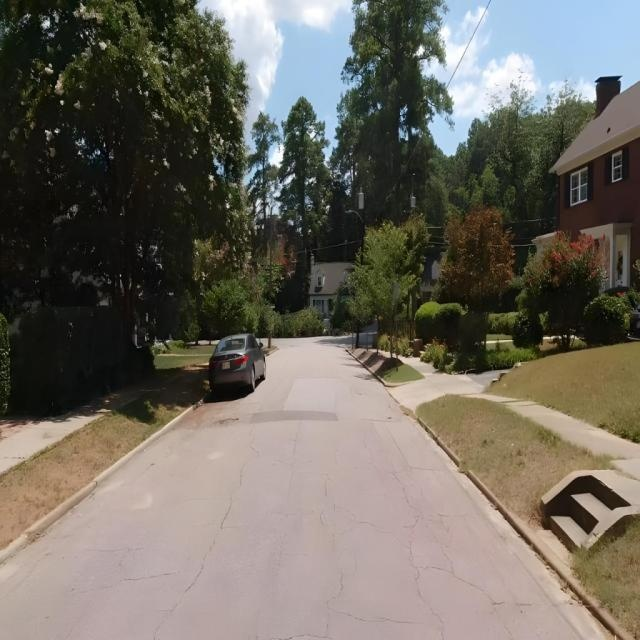

Image: Nuimages_5k.v1-main-version--march-24th.yolov8_test_n008-2018-06-05-15-07-28-0400__CAM_BACK_RIGHT__1528225842027813_jpg.rf.3a9bbfc5cdbcb4cc7ce23b5feddafb2d.jpg


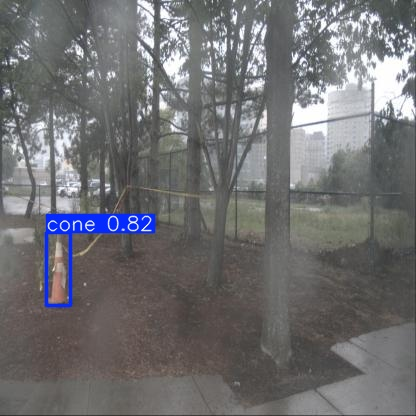

Image: stop_signs.v1i.yolov8_test_img_6465_png_jpg.rf.c89f80840d13beae690c5cc02f9d0f5c.jpg


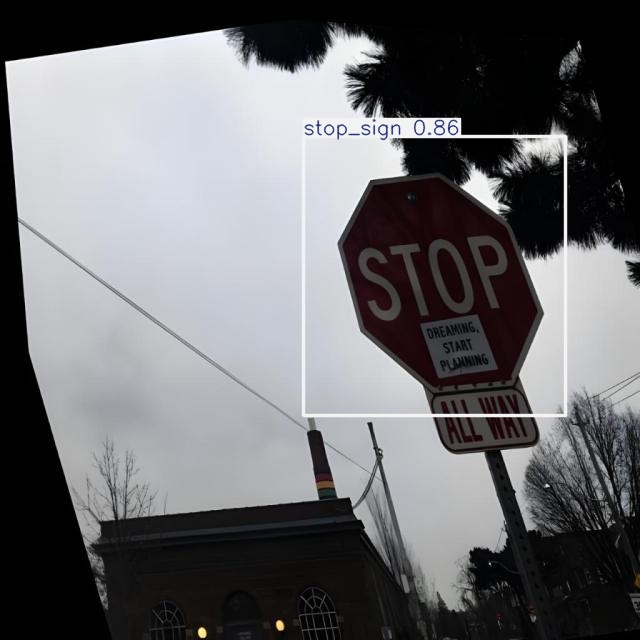

Image: Nuimages_5k.v1-main-version--march-24th.yolov8_test_n003-2018-01-02-14-02-53-0800__CAM_FRONT__1514874024657439_jpg.rf.e3f07540b7a3f26774f866cd14cbc1bb.jpg


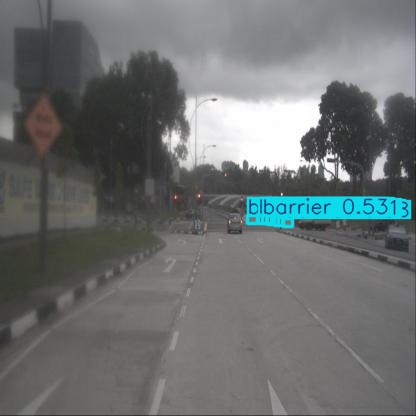

Image: stop_signs.v1i.yolov8_test_20180411_192659_s_png_jpg.rf.0850057c25dfd066ddb0d6efa07edcc1.jpg


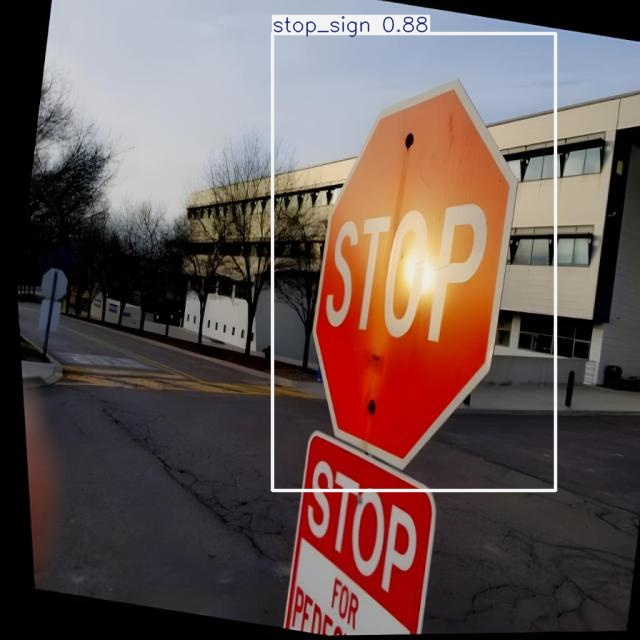

In [ ]:

from pathlib import Path
from IPython.display import display, Image
import random

test_dir = Path(
    "/content/robotics_navigation_dataset/images/test"
)

test_images = list(test_dir.glob("*"))

if not test_images:
    print("No test images found.")
else:
    selected_images = random.sample(
        test_images, min(5, len(test_images))
    )

    for image_path in selected_images:
        results = model.predict(
            source=str(image_path),
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False
        )

        output_path = results[0].save(
            filename="/content/prediction.jpg"
        )

        print(f"Image: {image_path.name}")
        display(Image(filename=output_path))


In [ ]:

from ultralytics import YOLO

model = YOLO(
    "/content/robotics_runs/eric_robotics_detector/weights/best.pt"
)

print("Classes:", model.names)


Classes: {0: 'cone', 1: 'barrier', 2: 'stop_sign'}


In [ ]:
from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import display
from PIL import Image
import io
import cv2
import numpy as np

try:
    # Capture a fresh frame from the webcam
    data = eval_js("window.captureFrame()")
    image_bytes = b64decode(data.split(",")[1])
    frame = np.array(Image.open(io.BytesIO(image_bytes)).convert("RGB"))

    # Run object detection
    results = model.predict(
        source=frame,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )

    # Display the detection results
    annotated = results[0].plot()
    display(Image.fromarray(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)))

    # Print detected classes and confidence
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.2%}")

except Exception as e:
    if "window.captureFrame" in str(e):
        print("\033[91mError: Webcam helper functions are not initialized in your browser.\033[0m")
        print("Please go back and run the webcam cell (RVs1Q7hWadnn) to start the camera before running this detection cell.")
    else:
        raise e

Error: Webcam helper functions are not initialized in your browser.
Please go back and run the webcam cell (RVs1Q7hWadnn) to start the camera before running this detection cell.


In [ ]:

from IPython.display import display, Javascript

display(Javascript("""
(async () => {
    if (window.robotStream) {
        window.robotStream.getTracks().forEach(t => t.stop());
    }

    const div = document.createElement('div');
    div.id = 'robot-live-camera';

    const video = document.createElement('video');
    video.width = 640;
    video.autoplay = true;
    video.playsInline = true;
    video.style.width = '640px';
    video.style.maxWidth = '100%';
    video.style.display = 'block';

    div.appendChild(video);
    document.body.appendChild(div);

    try {
        const stream = await navigator.mediaDevices.getUserMedia({
            video: true,
            audio: false
        });

        window.robotStream = stream;
        video.srcObject = stream;
        await video.play();

        window.robotVideo = video;
        window.captureFrame = () => {
            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            return canvas.toDataURL('image/jpeg');
        };

        console.log("Webcam ready:", video.videoWidth, video.videoHeight);
    } catch (e) {
        console.error("Camera error:", e);
    }
})();
"""))


In [ ]:
import time
import io
import torch
import numpy as np

from PIL import Image
from base64 import b64decode
from IPython.display import display
from google.colab.output import eval_js
from ultralytics import YOLO
import cv2

# Load the trained model
model = YOLO(
    "/content/robotics_runs/eric_robotics_detector/weights/best.pt"
)

device = 0 if torch.cuda.is_available() else "cpu"
print("Running on:", "GPU" if device == 0 else "CPU")
print("Classes:", model.names)

# Create an output area that updates continuously
live_output = display("Starting detection...", display_id=True)

try:
    while True:
        try:
            # Capture the latest webcam frame
            data = eval_js("window.captureFrame()")
        except Exception as js_err:
            if "window.captureFrame" in str(js_err):
                live_output.update("Error: Live camera feed is not running. Please run cell dAH7Cc2gbSM1 above first to initialize your webcam.")
                time.sleep(2)
                continue
            else:
                raise js_err

        image_bytes = b64decode(data.split(",")[1])
        frame = np.array(
            Image.open(io.BytesIO(image_bytes)).convert("RGB")
        )

        start = time.perf_counter()

        # Run YOLO detection
        results = model.predict(
            source=frame,
            imgsz=640,
            conf=0.15,
            iou=0.45,
            device=device,
            verbose=False
        )

        elapsed = time.perf_counter() - start
        fps = 1.0 / max(elapsed, 1e-6)

        # Draw bounding boxes
        annotated = results[0].plot()
        annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        # Add FPS and detection information
        count = len(results[0].boxes)
        cv2.putText(
            annotated,
            f"Inference: {elapsed * 1000:.1f} ms | FPS: {fps:.1f}",
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        live_output.update(Image.fromarray(annotated))

        if count:
            detected = [
                f"{model.names[int(b.cls[0])]} "
                f"({float(b.conf[0]):.2f})"
                for b in results[0].boxes
            ]
            print("Detected:", ", ".join(detected))

except KeyboardInterrupt:
    print("Live detection stopped.")

Running on: GPU
Classes: {0: 'cone', 1: 'barrier', 2: 'stop_sign'}


'Error: Live camera feed is not running. Please run cell dAH7Cc2gbSM1 above first to initialize your webcam.'

Live detection stopped.
